# Fraud Detection with Anomaly Detection

**Goal.** Detect fraudulent card transactions as *anomalies*: transactions that look unlike normal spending, found without relying on fraud labels to train the detector.

Two unsupervised approaches are compared:

* **Isolation Forest**, which isolates unusual points with random partitions. It is fitted without labels.
* **Autoencoder** (PyTorch), trained to reconstruct normal transactions. Fraud reconstructs poorly, so reconstruction error serves as the anomaly score.

A supervised model trained *with* labels is reported alongside as a reference, to show how much the labels are worth.

**Data:** the ULB / Worldline credit-card fraud dataset (Dal Pozzolo et al., 2015). It holds 284,807 European card transactions over two days in September 2013, of which 492 (0.173%) are fraudulent. Features `V1`–`V28` are PCA components released in place of the confidential raw features; `Time` and `Amount` are untransformed.

**Evaluation:** precision, recall and F1 at an alert threshold chosen on a validation period, plus threshold-free precision–recall AUC. With 0.17% positives, accuracy and ROC-AUC alone would be misleading.

## 1. Setup and data

In [1]:
import hashlib, time
from pathlib import Path
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.ensemble import IsolationForest, HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             precision_score, recall_score, f1_score, confusion_matrix)

SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

# The original Kaggle file (mlg-ulb/creditcardfraud), mirrored unchanged on GitHub because Kaggle needs a login.
DATA_URL = "https://raw.githubusercontent.com/stat432/credit-analysis/main/data-raw/creditcard.csv.zip"
DATA_SHA256 = "d9ade8e5a6c7b39cf3afef2de0fc10ecf9337c2cebdc6cc59a54b1d9dce007cc"
DATA_PATH = Path("data/creditcard.csv.zip")

if not DATA_PATH.exists():
    DATA_PATH.parent.mkdir(exist_ok=True)
    print("Downloading", DATA_URL)
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)
digest = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
assert digest == DATA_SHA256, f"checksum mismatch: {digest}"

df = pd.read_csv(DATA_PATH)
print(df.shape, f"| frauds: {df.Class.sum()} ({df.Class.mean():.3%}) | missing values: {df.isna().sum().sum()}")
assert len(df) == 284_807 and df.Class.sum() == 492   # matches the published dataset description

(284807, 31) | frauds: 492 (0.173%) | missing values: 0


## 2. Exploratory analysis

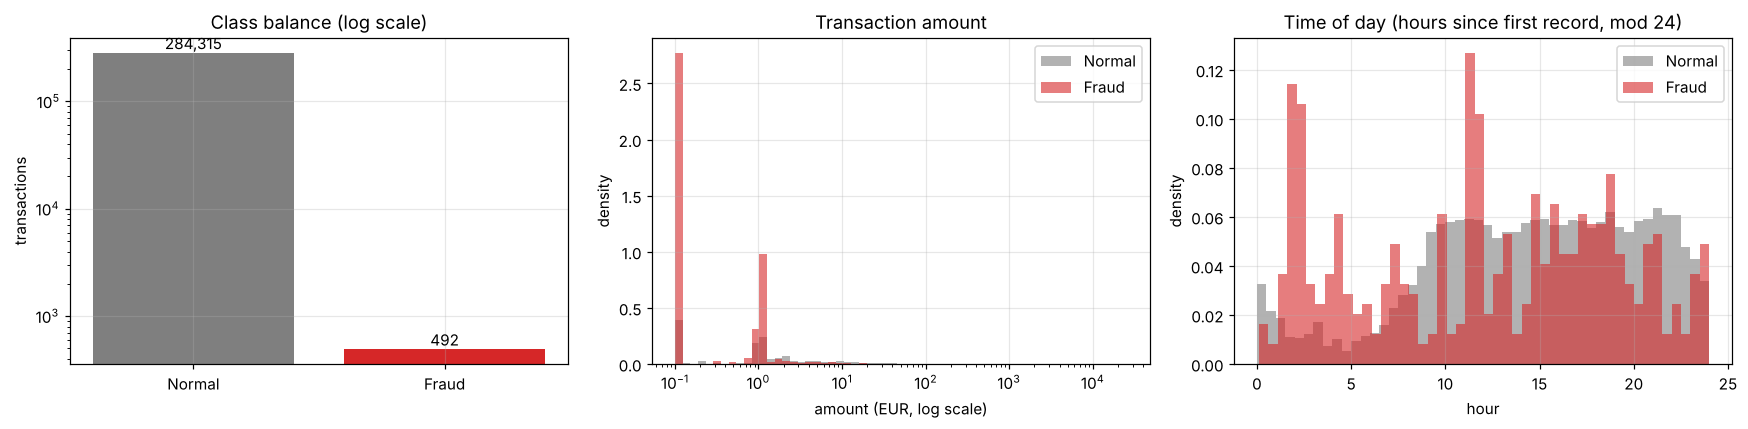

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,88.29,250.11,0.0,5.65,22.00,77.05,25691.16
1,492.0,122.21,256.68,0.0,1.00,9.25,105.89,2125.87


In [2]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
ax = axes[0]
counts = df.Class.value_counts().sort_index()
ax.bar(["Normal", "Fraud"], counts.values, color=["tab:gray", "tab:red"])
ax.set_yscale("log"); ax.set(title="Class balance (log scale)", ylabel="transactions")
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom")

ax = axes[1]
bins = np.logspace(-1, np.log10(df.Amount.max() + 1), 60)
ax.hist(df.loc[df.Class == 0, "Amount"] + 0.1, bins=bins, density=True, alpha=0.6, color="tab:gray", label="Normal")
ax.hist(df.loc[df.Class == 1, "Amount"] + 0.1, bins=bins, density=True, alpha=0.6, color="tab:red", label="Fraud")
ax.set_xscale("log"); ax.set(title="Transaction amount", xlabel="amount (EUR, log scale)", ylabel="density"); ax.legend()

ax = axes[2]
hours = (df.Time % 86400) / 3600
ax.hist(hours[df.Class == 0], bins=48, density=True, alpha=0.6, color="tab:gray", label="Normal")
ax.hist(hours[df.Class == 1], bins=48, density=True, alpha=0.6, color="tab:red", label="Fraud")
ax.set(title="Time of day (hours since first record, mod 24)", xlabel="hour", ylabel="density"); ax.legend()
plt.tight_layout(); plt.show()

df.groupby("Class").Amount.describe().round(2)

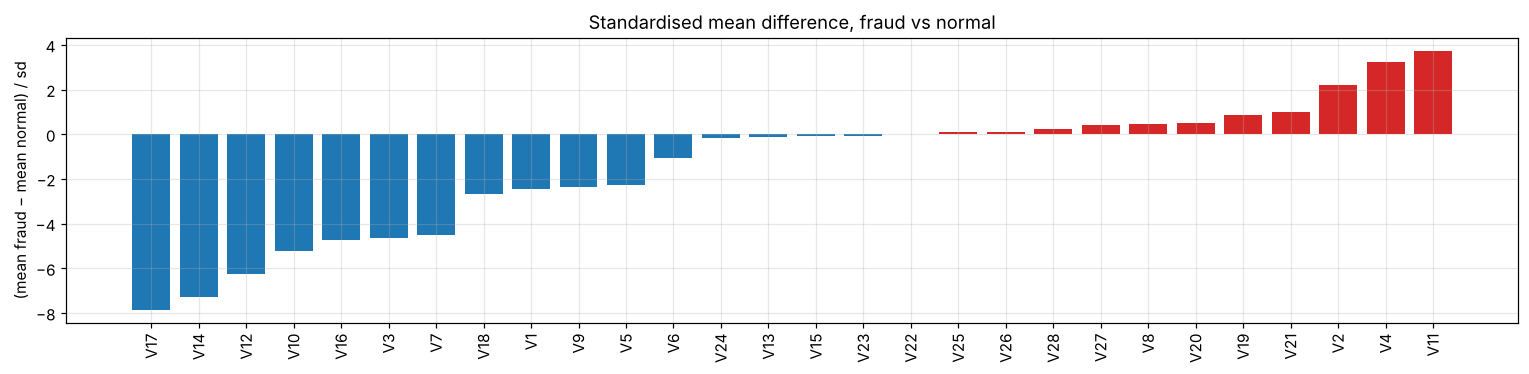

In [3]:
# Which PCA components separate the classes most? (standardised mean difference)
feat = [f"V{i}" for i in range(1, 29)]
smd = ((df.loc[df.Class == 1, feat].mean() - df.loc[df.Class == 0, feat].mean()) / df[feat].std()).sort_values()
fig, ax = plt.subplots(figsize=(14, 3.5))
ax.bar(smd.index, smd.values, color=np.where(smd.values < 0, "tab:blue", "tab:red"))
ax.set(title="Standardised mean difference, fraud vs normal", ylabel="(mean fraud − mean normal) / sd")
plt.xticks(rotation=90); plt.tight_layout(); plt.show()

## 3. Features and a time-ordered split

A random split would let the model see transactions from the same period it is tested on. Instead the data are ordered by `Time`, and models are fitted on the earliest 60%, tuned on the next 20%, and tested on the final 20%, as they would be in deployment.

Features are `V1`–`V28`, log(1 + amount), and the hour of day encoded as sine and cosine. The scaler is fitted on the training period only.

In [4]:
df = df.sort_values("Time").reset_index(drop=True)
X_all = df[feat].copy()
X_all["log_amount"] = np.log1p(df.Amount)
hour = (df.Time % 86400) / 3600
X_all["hour_sin"], X_all["hour_cos"] = np.sin(2 * np.pi * hour / 24), np.cos(2 * np.pi * hour / 24)
y_all = df.Class.values
FEATURES = list(X_all.columns)

n = len(df)
i_tr, i_va = int(0.6 * n), int(0.8 * n)
splits = {"train": slice(0, i_tr), "validation": slice(i_tr, i_va), "test": slice(i_va, n)}
scaler = StandardScaler().fit(X_all.iloc[splits["train"]])
X = {k: scaler.transform(X_all.iloc[s]).astype(np.float32) for k, s in splits.items()}
y = {k: y_all[s] for k, s in splits.items()}
pd.DataFrame({k: {"transactions": len(y[k]), "frauds": int(y[k].sum()), "fraud rate": f"{y[k].mean():.3%}",
                  "time span (h)": f"{df.Time.iloc[s].min() / 3600:.1f}–{df.Time.iloc[s].max() / 3600:.1f}"}
              for k, s in splits.items()}).T

,transactions,frauds,fraud rate,time span (h)
train,170884,360,0.211%,0.0–33.4
validation,56961,57,0.100%,33.4–40.3
test,56962,75,0.132%,40.3–48.0


## 4. Evaluation helpers

Every model outputs an anomaly score where higher means more suspicious. The alert threshold maximises F1 on the **validation** period and is then applied unchanged to the test period.

In [5]:
def choose_threshold(y_true, score):
    p, r, t = precision_recall_curve(y_true, score)
    f1 = 2 * p * r / np.clip(p + r, 1e-12, None)
    best = np.nanargmax(f1[:-1])
    return t[best]


def evaluate(name, score_va, score_te):
    thr = choose_threshold(y["validation"], score_va)
    pred = (score_te >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y["test"], pred).ravel()
    return {"model": name, "PR-AUC": average_precision_score(y["test"], score_te),
            "ROC-AUC": roc_auc_score(y["test"], score_te),
            "precision": precision_score(y["test"], pred, zero_division=0),
            "recall": recall_score(y["test"], pred), "F1": f1_score(y["test"], pred),
            "alerts": int(tp + fp), "frauds caught": int(tp), "frauds missed": int(fn), "false alarms": int(fp),
            "threshold": thr}


results, scores = [], {}

## 5. Isolation Forest (unsupervised)

Fitted on all training-period transactions, without labels.

In [6]:
t0 = time.time()
iso = IsolationForest(n_estimators=400, max_samples=4096, contamination="auto", random_state=SEED, n_jobs=-1)
iso.fit(X["train"])
scores["Isolation Forest"] = {k: -iso.score_samples(X[k]) for k in ("validation", "test")}
results.append(evaluate("Isolation Forest", *scores["Isolation Forest"].values()))
print(f"fitted in {time.time() - t0:.1f}s")
pd.DataFrame(results).set_index("model").round(3)

fitted in 3.2s


,PR-AUC,ROC-AUC,precision,recall,F1,alerts,frauds caught,frauds missed,false alarms,threshold
model,,,,,,,,,,
Isolation Forest,0.063,0.954,0.092,0.533,0.157,434,40,35,394,0.521


## 6. Autoencoder (deep, trained on normal behaviour)

A symmetric autoencoder (31 → 20 → 10 → 5 → 10 → 20 → 31) is trained to reconstruct **normal** training transactions only. This is the novelty-detection setting: labels are used only to leave known frauds out of the training data, never to learn what fraud looks like. It is trained for up to 60 epochs, keeping the weights with the lowest reconstruction loss on normal validation transactions (training stops early if that loss stops improving). The anomaly score is the mean squared reconstruction error.

In [7]:
class Autoencoder(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.encoder = nn.Sequential(nn.Linear(d, 20), nn.ELU(), nn.Linear(20, 10), nn.ELU(), nn.Linear(10, 5))
        self.decoder = nn.Sequential(nn.ELU(), nn.Linear(5, 10), nn.ELU(), nn.Linear(10, 20), nn.ELU(), nn.Linear(20, d))

    def forward(self, x):
        return self.decoder(self.encoder(x))


Xtr_norm = torch.tensor(X["train"][y["train"] == 0])
Xva_norm = torch.tensor(X["validation"][y["validation"] == 0])
ae = Autoencoder(Xtr_norm.shape[1])
opt = torch.optim.Adam(ae.parameters(), lr=1e-3, weight_decay=1e-5)
loss_fn = nn.MSELoss()
hist, best, best_state, wait = [], np.inf, None, 0
t0 = time.time()
for epoch in range(1, 61):
    ae.train()
    perm = torch.randperm(len(Xtr_norm))
    tot = 0.0
    for i in range(0, len(perm), 512):
        xb = Xtr_norm[perm[i:i + 512]]
        opt.zero_grad(); loss = loss_fn(ae(xb), xb); loss.backward(); opt.step()
        tot += loss.item() * len(xb)
    ae.eval()
    with torch.no_grad():
        val = loss_fn(ae(Xva_norm), Xva_norm).item()
    hist.append((epoch, tot / len(Xtr_norm), val))
    if val < best - 1e-5:
        best, best_state, wait = val, {k: v.clone() for k, v in ae.state_dict().items()}, 0
    else:
        wait += 1
    if wait >= 6:
        break
ae.load_state_dict(best_state)
print(f"stopped after {epoch} epochs in {time.time() - t0:.0f}s; best normal-validation MSE {best:.4f}")


def recon_error(model, Xn):
    model.eval()
    with torch.no_grad():
        xt = torch.tensor(Xn)
        return ((model(xt) - xt) ** 2).mean(1).numpy()

scores["Autoencoder"] = {k: recon_error(ae, X[k]) for k in ("validation", "test")}
results.append(evaluate("Autoencoder", *scores["Autoencoder"].values()))
pd.DataFrame(results).set_index("model").round(3)

stopped after 60 epochs in 21s; best normal-validation MSE 0.6070


,PR-AUC,ROC-AUC,precision,recall,F1,alerts,frauds caught,frauds missed,false alarms,threshold
model,,,,,,,,,,
Isolation Forest,0.063,0.954,0.092,0.533,0.157,434,40,35,394,0.521
Autoencoder,0.175,0.956,0.306,0.293,0.299,72,22,53,50,7.584


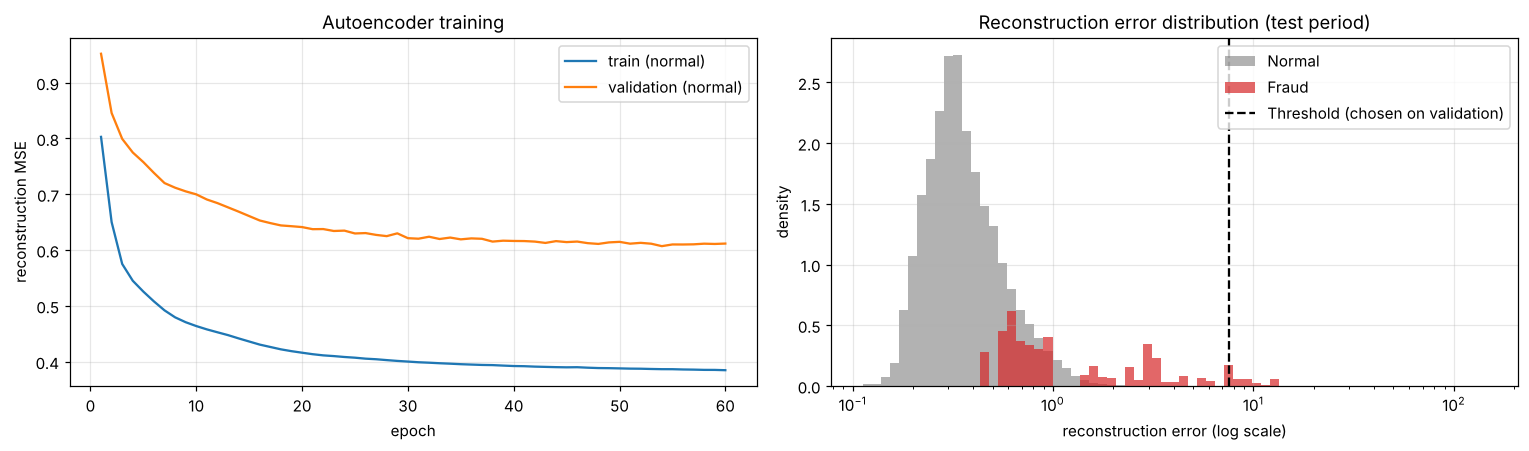

In [8]:
h = pd.DataFrame(hist, columns=["epoch", "train", "validation"])
thr_ae = results[-1]["threshold"]
err_te = scores["Autoencoder"]["test"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].plot(h.epoch, h.train, label="train (normal)"); axes[0].plot(h.epoch, h.validation, label="validation (normal)")
axes[0].set(title="Autoencoder training", xlabel="epoch", ylabel="reconstruction MSE"); axes[0].legend()
ax = axes[1]
bins = np.logspace(np.log10(err_te.min()), np.log10(err_te.max()), 70)
ax.hist(err_te[y["test"] == 0], bins=bins, density=True, alpha=0.6, color="tab:gray", label="Normal")
ax.hist(err_te[y["test"] == 1], bins=bins, density=True, alpha=0.7, color="tab:red", label="Fraud")
ax.axvline(thr_ae, ls="--", c="k", label="Threshold (chosen on validation)")
ax.set_xscale("log"); ax.set(title="Reconstruction error distribution (test period)", xlabel="reconstruction error (log scale)", ylabel="density")
ax.legend(); plt.tight_layout(); plt.show()

**Which features give fraud away?** Comparing per-feature reconstruction error for fraud and normal test transactions shows where the autoencoder's notion of "normal" breaks.

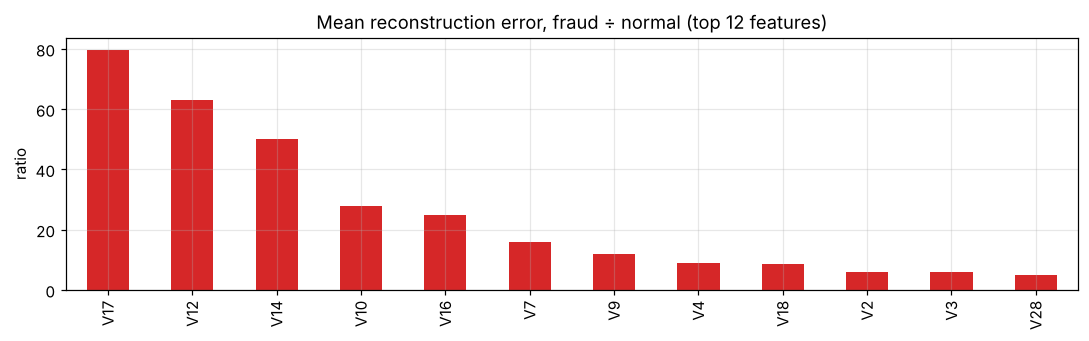

In [9]:
with torch.no_grad():
    xt = torch.tensor(X["test"])
    per_feat = ((ae(xt) - xt) ** 2).numpy()
ratio = pd.Series(per_feat[y["test"] == 1].mean(0) / per_feat[y["test"] == 0].mean(0), index=FEATURES).sort_values(ascending=False)
ax = ratio.head(12).plot.bar(figsize=(10, 3.2), color="tab:red", title="Mean reconstruction error, fraud ÷ normal (top 12 features)")
ax.set_ylabel("ratio"); plt.tight_layout(); plt.show()

## 7. Combined score and supervised reference

* **Ensemble (unsupervised):** the average of the two models' percentile ranks.
* **Supervised reference:** a gradient-boosted tree classifier trained on the labelled training period. This is *not* anomaly detection. It shows what becomes possible once enough confirmed fraud cases have been collected, and so puts the unsupervised results in context.

In [10]:
def pct_rank(a, ref):
    return np.searchsorted(np.sort(ref), a) / len(ref)

ref_if, ref_ae = -iso.score_samples(X["train"]), recon_error(ae, X["train"])
scores["Ensemble (IF + AE)"] = {k: 0.5 * (pct_rank(scores["Isolation Forest"][k], ref_if) + pct_rank(scores["Autoencoder"][k], ref_ae))
                                for k in ("validation", "test")}
results.append(evaluate("Ensemble (IF + AE)", *scores["Ensemble (IF + AE)"].values()))

t0 = time.time()
gbm = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, class_weight="balanced", random_state=SEED)
gbm.fit(X["train"], y["train"])
scores["Supervised GBM (reference)"] = {k: gbm.predict_proba(X[k])[:, 1] for k in ("validation", "test")}
results.append(evaluate("Supervised GBM (reference)", *scores["Supervised GBM (reference)"].values()))
print(f"GBM fitted in {time.time() - t0:.1f}s")

res = pd.DataFrame(results).set_index("model")
res.drop(columns="threshold").style.format({c: "{:.3f}" for c in ["PR-AUC", "ROC-AUC", "precision", "recall", "F1"]})

GBM fitted in 11.2s


,PR-AUC,ROC-AUC,precision,recall,F1,alerts,frauds caught,frauds missed,false alarms
model,,,,,,,,,
Isolation Forest,0.063,0.954,0.092,0.533,0.157,434,40,35,394
Autoencoder,0.175,0.956,0.306,0.293,0.299,72,22,53,50
Ensemble (IF + AE),0.133,0.960,0.207,0.560,0.302,203,42,33,161
Supervised GBM (reference),0.748,0.957,0.879,0.680,0.767,58,51,24,7


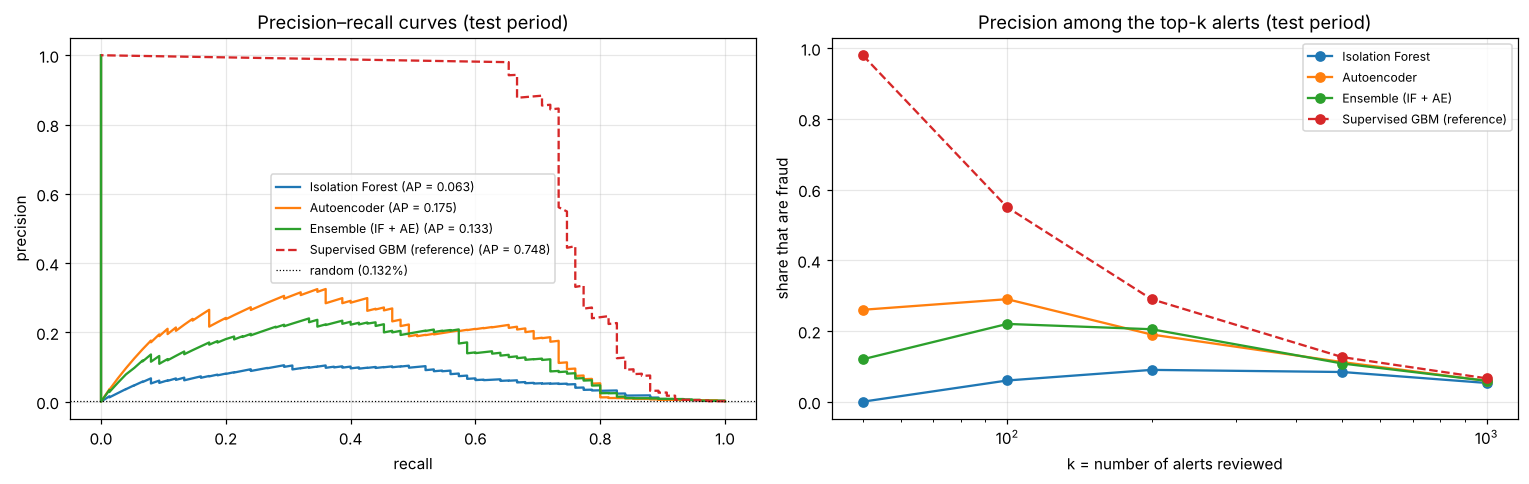

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
ax = axes[0]
for name, s in scores.items():
    p, r, _ = precision_recall_curve(y["test"], s["test"])
    ax.plot(r, p, label=f"{name} (AP = {average_precision_score(y['test'], s['test']):.3f})",
            ls="--" if "Supervised" in name else "-")
ax.axhline(y["test"].mean(), c="k", lw=0.8, ls=":", label=f"random ({y['test'].mean():.3%})")
ax.set(title="Precision–recall curves (test period)", xlabel="recall", ylabel="precision"); ax.legend(fontsize=8)

ax = axes[1]
ks = [50, 100, 200, 500, 1000]
for name, s in scores.items():
    order = np.argsort(-s["test"])
    ax.plot(ks, [y["test"][order[:k]].mean() for k in ks], marker="o", label=name, ls="--" if "Supervised" in name else "-")
ax.set(title="Precision among the top-k alerts (test period)", xlabel="k = number of alerts reviewed", ylabel="share that are fraud")
ax.set_xscale("log"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 8. Visualising anomalies with t-SNE

A 2-D t-SNE embedding of a test-period sample: all test frauds plus 3,000 randomly chosen normal transactions. The left panel colours points by true label; the right by whether the unsupervised ensemble raised an alert. t-SNE is for illustration only: distances in the embedding are not used by any model.

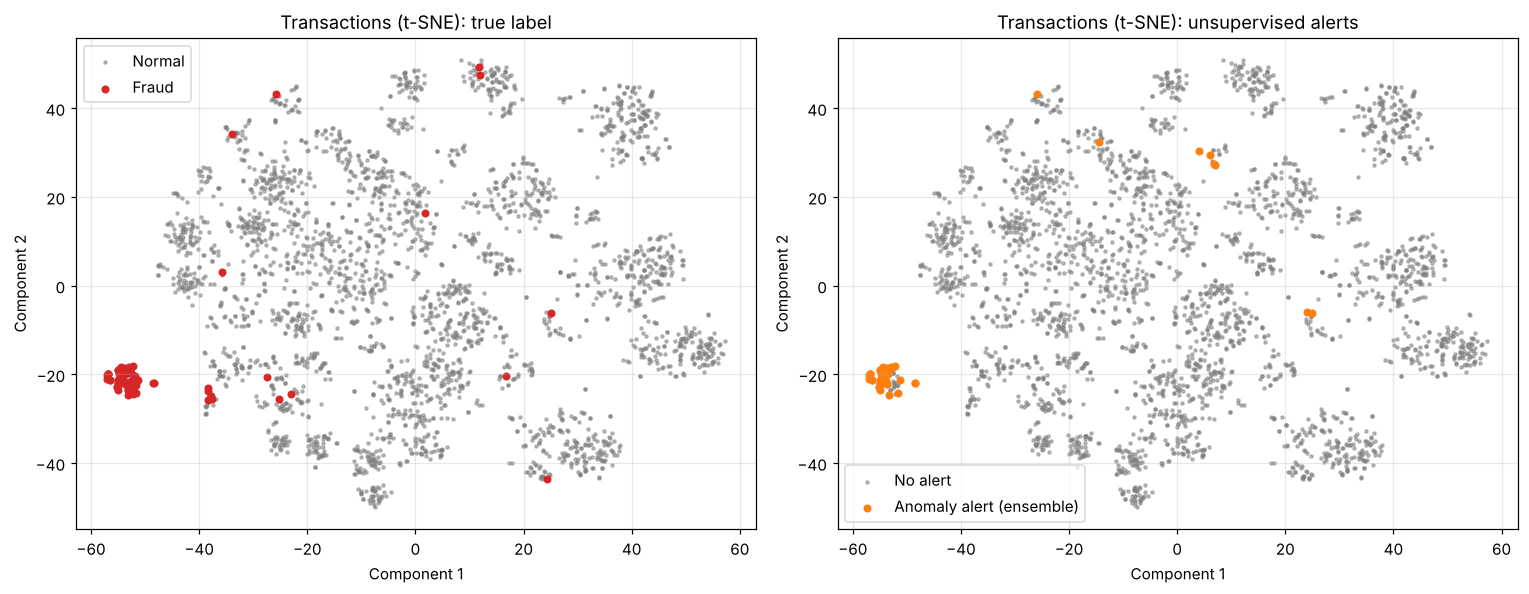

In [12]:
rng = np.random.default_rng(SEED)
idx_f = np.where(y["test"] == 1)[0]
idx_n = rng.choice(np.where(y["test"] == 0)[0], 3000, replace=False)
idx = np.concatenate([idx_n, idx_f])
emb = TSNE(n_components=2, perplexity=40, init="pca", random_state=SEED).fit_transform(X["test"][idx])
alert = scores["Ensemble (IF + AE)"]["test"][idx] >= res.loc["Ensemble (IF + AE)", "threshold"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
lab = y["test"][idx]
axes[0].scatter(*emb[lab == 0].T, s=4, c="tab:gray", alpha=0.5, label="Normal")
axes[0].scatter(*emb[lab == 1].T, s=18, c="tab:red", label="Fraud")
axes[0].set(title="Transactions (t-SNE): true label", xlabel="Component 1", ylabel="Component 2"); axes[0].legend()
axes[1].scatter(*emb[~alert].T, s=4, c="tab:gray", alpha=0.5, label="No alert")
axes[1].scatter(*emb[alert].T, s=18, c="tab:orange", label="Anomaly alert (ensemble)")
axes[1].set(title="Transactions (t-SNE): unsupervised alerts", xlabel="Component 1", ylabel="Component 2"); axes[1].legend()
plt.tight_layout(); plt.show()

## 9. Results and discussion

In [13]:
best_unsup = res.drop(index="Supervised GBM (reference)")["PR-AUC"].idxmax()
print("Test period:", len(y["test"]), "transactions,", int(y["test"].sum()), "frauds")
print("Best unsupervised model by PR-AUC:", best_unsup)
res[["PR-AUC", "precision", "recall", "F1", "frauds caught", "false alarms"]].round(3)

Test period: 56962 transactions, 75 frauds
Best unsupervised model by PR-AUC: Autoencoder


,PR-AUC,precision,recall,F1,frauds caught,false alarms
model,,,,,,
Isolation Forest,0.063,0.092,0.533,0.157,40,394
Autoencoder,0.175,0.306,0.293,0.299,22,50
Ensemble (IF + AE),0.133,0.207,0.560,0.302,42,161
Supervised GBM (reference),0.748,0.879,0.680,0.767,51,7


**How to read the results**

* **PR-AUC** summarises ranking quality across all thresholds. A random scorer scores roughly the fraud rate (about 0.002 here). **Precision, recall and F1** describe one operating point: the threshold that maximised F1 on the validation period, carried over to the test period unchanged.
* The **autoencoder** and **Isolation Forest** both rank fraud far above random without learning from fraud labels. The reconstruction-error histogram shows why: most frauds sit in the tail of normal behaviour, though they overlap with a minority of unusual but legitimate transactions.
* The **supervised reference** is clearly stronger. That is expected: once confirmed fraud cases exist, a classifier can learn their specific patterns. Unsupervised detectors are most useful when labels are scarce or delayed, or for new fraud patterns not yet in the labels. Their alerts can also seed the labelling that supervised models need.
* The **top-k precision** chart is the operational view: of the k transactions an analyst team could review, how many are actually fraud.

**Limitations.** The data cover only two days from one European issuer in 2013. The PCA-anonymised features prevent domain-level interpretation. With roughly a hundred frauds in each evaluation period, the metrics carry sampling uncertainty. A production system would need cost-sensitive thresholds, monitoring for drift, and evaluation over longer periods.

In [14]:
print({"numpy": np.__version__, "pandas": pd.__version__, "torch": torch.__version__,
       "scikit-learn": __import__("sklearn").__version__})

{'numpy': '2.5.3', 'pandas': '3.0.5', 'torch': '2.15.0+cu132', 'scikit-learn': '1.9.1'}
